# Classical baselines and exact refinement

**Версия 0.1.0a8.** Ноутбук проверяет Goemans–Williamson (SDP + округление),
классический simulated annealing, точную условную переоптимизацию блока и
обёртку `base solver → refiner`.

Все методы работают на CPU. `num_reads` отжига — это не квантовые шоты.
`E=-C`, поэтому хорошее значение отжига и глобальный разрез сравниваются в
одних единицах.

In [1]:
from pathlib import Path
from copy import deepcopy
import json
import tempfile

import numpy as np

import QA_max_cut_lib
from QA_max_cut_lib import (
    WeightedGraph, ExactCPU, GoemansWilliamsonCPU, SimulatedAnnealingCPU,
    ExactBlockRefiner, RefinedSolver, tools,
)
from QA_max_cut_lib.solvers.gpu_state import gpu_available

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
print("version:", QA_max_cut_lib.__version__)
print("package:", Path(QA_max_cut_lib.__file__).resolve())
assert QA_max_cut_lib.__version__ == "0.1.0a8"
print("GPU available:", gpu_available())

version: 0.1.0a8
package: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\.venv\Lib\site-packages\QA_max_cut_lib\__init__.py


GPU available: True


## 1. Знак BQM и полное назначение

Положительное ребро предпочитает разные спины, отрицательное — одинаковые.
Изолированная вершина остаётся в результате.

In [2]:
for weight in (2.0, -2.0):
    graph = WeightedGraph([(10, 30, weight)], nodes=[10, 30, 80])
    config = tools.load_json(PROJECT / "configs/solvers/simulated_annealing_cpu.json")
    config["num_treads"] = 1
    config["parameters"].update(num_reads=4, num_sweeps=16)
    config["limits"] = {"anneal_reads_total": 4, "anneal_sweeps_total": 64}
    solver = SimulatedAnnealingCPU(config)
    solution = solver.solve(graph, report=0, logs=0)
    metrics = tools.analyze_solution(graph, solution)
    print(weight, solution, "C=", metrics["cut_value"],
          "BQM offset=", solver.bqm_offset)
    assert set(solution) == {10, 30, 80}
    assert metrics["cut_value"] == graph.cut_value(solution)
    if weight > 0:
        assert metrics["cut_value"] >= 0.0
    else:
        assert metrics["cut_value"] <= 0.0

2.0 {10: 1, 30: -1, 80: -1} C= 2.0 BQM offset= -1.0
-2.0 {10: 1, 30: 1, 80: 1} C= 0.0 BQM offset= 1.0


## 2. ExactCPU как малый эталон

ExactCPU решает полный граф, а не блок. Его `C` служит эталоном качества
только для этой малой задачи; GW-разрез сам по себе эталоном не является.

In [3]:
small = WeightedGraph(
    [(10,30,1),(10,80,4),(30,80,3),(10,101,-1),(80,101,2)],
    nodes=[10,30,80,101],
)
exact = ExactCPU({"parameters": {"max_vertices": 8}})
exact_solution = exact.solve(small, report=0, logs=0)
exact_metrics = tools.analyze_solution(small, exact_solution)
print("exact:", exact_solution, exact_metrics["cut_value"])
assert exact_metrics["cut_value"] == small.cut_value(exact_solution)

exact: {10: 1, 30: 1, 80: -1, 101: 1} 9.0


## 3. Goemans–Williamson

SDP-значение — численное значение релаксации, не сертифицированная верхняя
граница. Округление использует независимые гиперплоскости.

In [4]:
triangle = WeightedGraph(
    [(10,30,1),(10,80,1),(30,80,1)], nodes=[10,30,80]
)
gw_config = tools.load_json(PROJECT / "configs/solvers/gw_cpu.json")
gw_config["parameters"]["num_hyperplanes"] = 8
gw = GoemansWilliamsonCPU(gw_config)
gw_solution = gw.solve(triangle, report=0, logs=0)
gw_metrics = tools.analyze_solution(triangle, gw_solution)
print("GW solution:", gw_solution, "C=", gw_metrics["cut_value"])
print("SDP:", gw.sdp_objective_raw, gw.sdp_status,
      "min eigen:", gw.sdp_diagnostics["minimum_eigenvalue"])
print("bound:", gw.sdp_upper_bound, gw.sdp_upper_bound_reason)
assert gw.sdp_status == "optimal"
assert abs(gw.sdp_objective_raw - 2.25) < 1e-4
assert set(gw_solution) == {10,30,80}

GW solution: {10: 1, 30: -1, 80: -1} C= 2.0
SDP: 2.2500000008801218 optimal min eigen: -1.1714063052892243e-09
bound: None No strict dual certificate is built in this milestone.


## 4. Отжиг: reads, sweeps, seeds

Один read — один независимый запуск. Все reads получают seeds из корневого
seed и логического `read_id`, а не из порядка завершения.

In [5]:
sa_config = tools.load_json(PROJECT / "configs/solvers/simulated_annealing_cpu.json")
sa_config["num_treads"] = 1
sa_config["parameters"].update(num_reads=6, num_sweeps=32)
sa_config["limits"] = {"anneal_reads_total": 6, "anneal_sweeps_total": 192}
sa = SimulatedAnnealingCPU(sa_config)
sa_solution = sa.solve(small, report=0, logs=0)
print("SA C:", sa.cut_value, "reads:", sa.num_reads_completed,
      "sweeps:", sa.num_sweeps_accounted)
print("seeds:", sa.seed_plan)
assert sa.num_reads_completed == 6
assert sa.num_sweeps_accounted == 192
assert len(set(sa.seed_plan)) == 6

SA C: 9.0 reads: 6 sweeps: 192
seeds: [955475868, 1385871029, 1939820029, 627778343, 2097342444, 142140079]


## 5. Условная задача FineTuning

В блоке `S={10,30}` при `t_80=+1` есть граничные поля. Фиксация одного
внутреннего спина теряет условный оптимум; перебираются оба спина.

In [6]:
conditional_graph = WeightedGraph(
    [(10,30,1),(10,80,4),(30,80,3)], nodes=[10,30,80]
)
refiner_config = {
    "type": "exact_block",
    "parameters": {"max_size": 8, "batch_size": 4, "max_passes": 1},
    "selector": {"type": "explicit_blocks", "parameters": {"blocks": [[10,30]]}},
}
refiner = ExactBlockRefiner(refiner_config)
conditional_solution = refiner.refine(
    conditional_graph, {10:1,30:1,80:1}
)
print(conditional_solution, conditional_graph.cut_value(conditional_solution))
print("gain:", refiner.last_refinement["gain"])
assert conditional_solution == {10:-1,30:-1,80:1}
assert conditional_graph.cut_value(conditional_solution) == 7.0

{10: -1, 30: -1, 80: 1} 7.0
gain: 7.0


## 6. Последовательное применение блоков

Два независимых локальных улучшения нельзя складывать. `S1={10}` и
`S2={30}` на старом окружении оба предлагают `gain=1`, но одновременное
применение даёт `C=-4`. Последовательный refiner принимает только первую
коррекцию и пересчитывает поля.

In [7]:
sequential_graph = WeightedGraph(
    [(10,30,3),(10,80,-2),(30,80,-2)], nodes=[10,30,80]
)
sequential_config = {
    "type": "exact_block",
    "parameters": {"max_size": 8, "batch_size": 4, "max_passes": 2},
    "selector": {"type": "explicit_blocks", "parameters": {"blocks": [[10],[30]]}},
}
sequential = ExactBlockRefiner(sequential_config)
sequential_solution = sequential.refine(sequential_graph, {10:1,30:1,80:1})
print(sequential_solution, sequential_graph.cut_value(sequential_solution))
assert sequential_graph.cut_value(sequential_solution) == 1.0

{10: -1, 30: 1, 80: 1} 1.0


## 7. Обёртка над квантовым базовым решением

Базовая запись сохраняется отдельно. Углы, expected energy и quantum
распределения относятся к `base_run`, а не к классически улучшенному
назначению.

In [8]:
base_graph = WeightedGraph(
    [(0,1,1),(1,2,-2),(2,3,2),(3,4,1)], nodes=list(range(5))
)
refined_config = tools.load_json(PROJECT / "configs/solvers/refined_qaoa_cpu.json")
refined = RefinedSolver(refined_config)
refined_solution = refined.solve(base_graph, report=0, logs=0)
print("base:", refined.base_cut_value, "final:", refined.cut_value,
      "gain:", refined.gain)
print("base algorithm:", refined.base_run["algorithm_type"])
assert set(refined_solution) == set(base_graph.nodes)
assert refined.cut_value >= refined.base_cut_value
assert refined.base_run["algorithm_type"] == "qaoa_cpu"

base: 4.0 final: 4.0 gain: 0.0
base algorithm: qaoa_cpu


## 8. Метрики, графики и сохранение

{'complete': True, 'valid': True, 'node_count': 5, 'edge_count': 4, 'spin_values': [-1, 1], 'cut_value': 4.0, 'solution_energy': -4.0, 'separated_edge_count': 3, 'cut_weight': 4.0, 'cut_edges': [(0, 1, 1.0), (2, 3, 2.0), (3, 4, 1.0)], 'reference_cut': 4.0, 'reference_kind': 'heuristic_base', 'optimality_gap': 0.0, 'ratio': 1.0}


plots: Figure Figure Figure Figure
saved: C:\Users\Alexey\AppData\Local\Temp\classical_glxk0u9t\results\refined_example\refined_example.json loaded: refined


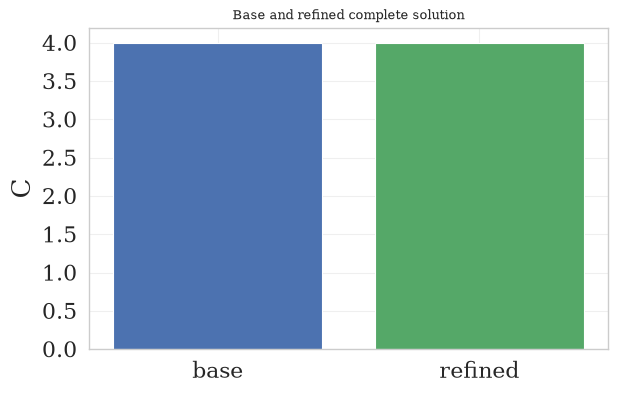

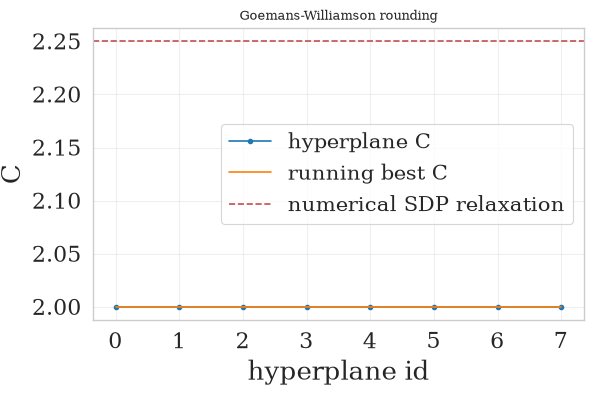

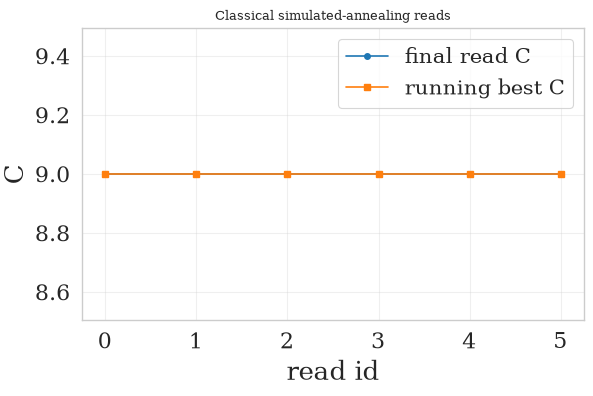

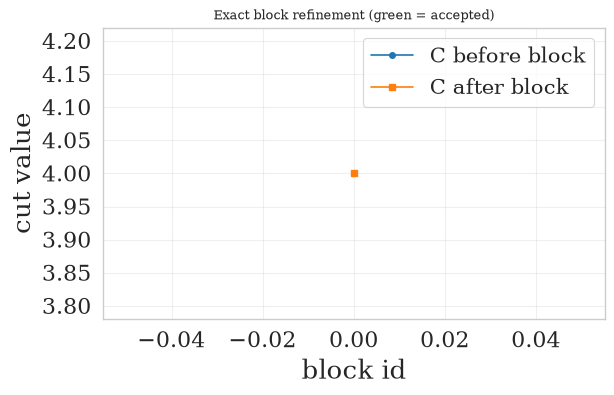

In [9]:
final_metrics = tools.analyze_solution(
    base_graph, refined_solution, reference_cut=refined.base_cut_value,
    reference_kind="heuristic_base",
)
print(final_metrics)
overview = tools.plot_classical_comparison(refined, {"style": {"figsize": [6,4]}})
gw_plot = tools.plot_gw_convergence(gw, {"style": {"figsize": [6,4]}})
sa_plot = tools.plot_sa_reads(sa, {"style": {"figsize": [6,4]}})
refine_plot = tools.plot_refinement(refined, {"style": {"figsize": [6,4]}})
print("plots:", type(overview).__name__, type(gw_plot).__name__,
      type(sa_plot).__name__, type(refine_plot).__name__)
with tempfile.TemporaryDirectory(prefix="classical_") as tmp:
    save = {
        "path": str(Path(tmp) / "results"),
        "atts": ["solution", "cut_value", "base_run", "refinement_run", "gain"],
        "filename": "refined_example",
        "save_original_data": [],
        "makedir": True,
        "savedir": True,
    }
    saved = tools.save_result(refined, save)
    loaded = tools.load_result(saved.primary)
    print("saved:", saved.primary, "loaded:", loaded.get("algorithm_type"))
    assert loaded.get("algorithm_type") == "refined"

## 9. Итог

In [10]:
print("version:", QA_max_cut_lib.__version__)
print("sign and isolate: ok")
print("GW SDP/rounding: ok")
print("SA reads/sweeps/seeds: ok")
print("conditional block: ok")
print("sequential refinement: ok")
print("refined base/record: ok")
print("GPU base available (not required):", gpu_available())

version: 0.1.0a8
sign and isolate: ok
GW SDP/rounding: ok
SA reads/sweeps/seeds: ok
conditional block: ok
sequential refinement: ok
refined base/record: ok
GPU base available (not required): True
